# Cyber-Physical Threat Detection Prototype

**Project:** Omni-Grid Renewable Energy Intelligence Platform  
**Model:** Cyber-Physical Threat Detection v1.0  
**Notebook purpose:** Build a detailed prototype that detects suspicious cyber-physical behaviour from inverter telemetry, operational events, and physical-process anomaly patterns.

## What this notebook does

This prototype builds a defensive threat-detection pipeline using the available dataset. The project requirement asks for Cyber-Physical Threat Detection across network traffic, SCADA commands, and user access logs. However, the provided dataset mainly contains inverter telemetry, operational events, electrical/thermal indicators, rolling health indicators, and failure labels.

Because raw firewall logs, packet-flow data, IAM logs, and SCADA command sequences are not included, this notebook implements the **physical-process anomaly layer** of the cyber-physical threat system. It uses telemetry deviations, restart/error bursts, electrical instability, thermal stress, insulation risk, and sudden control-like shifts as proxy signals for cyber-physical investigation.

In production, this model should be fused with real cyber logs such as:

- Network traffic features: source/destination, packet rate, connection frequency, protocol, port, payload size statistics.
- SCADA command logs: command type, command frequency, command sequence, setpoint changes, operator ID, device ID.
- IAM/access logs: login attempts, privileged actions, failed access attempts, unusual access time, geolocation/device metadata.

This prototype is therefore designed as a realistic foundation for the full cyber-physical system, while being honest about the limitations of the current synthetic dataset.

## Prototype Architecture

```text
Raw Dataset
  |
  |-- inverter metadata
  |-- operating conditions
  |-- electrical and thermal telemetry
  |-- restart/error/overload events
  |-- rolling health indicators
  v
Data Quality and Time Ordering
  v
Advanced Feature Engineering
  |-- physical process anomaly indicators
  |-- event burst indicators
  |-- electrical instability indicators
  |-- unsafe control-shift proxies
  |-- degradation and safety flags
  v
Weak Cyber-Physical Threat Labelling
  |-- creates prototype labels from high-risk telemetry and event patterns
  |-- must be replaced with real incident labels in production
  v
Model Layer
  |-- Decision Tree baseline
  |-- Random Forest classifier
  |-- Extra Trees classifier
  |-- optional XGBoost extension
  |-- Isolation Forest unsupervised anomaly detector
  v
Threat Fusion and SOC Output
  |-- threat probability
  |-- severity level
  |-- likely threat type
  |-- recommended operator action
  |-- exportable alert table
```

In [1]:
# ================================================================
# 1. Imports and notebook configuration
# ================================================================

import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.inspection import permutation_importance

import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 80)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# ================================================================
# Data paths (portable)
# ================================================================
# Run this notebook from its own module folder. Data lives in ./data.
# If the full synthetic dataset is not present, the sample file is used
# so the notebook still runs end to end for anyone who clones the repo.

DATA_DIR = Path.cwd() / "data"
DATASET_PATH = DATA_DIR / "synthetic_cpt_dataset.csv"
SAMPLE_PATH = DATA_DIR / "synthetic_cpt_sample.csv"
DICTIONARY_PATH = DATA_DIR / "synthetic_cpt_data_dictionary.csv"

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = PROJECT_DIR / "images"
for folder in [OUTPUT_DIR, MODEL_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset path:", DATASET_PATH)


In [3]:
# ================================================================
# 3. Load dataset, dictionary, and sample file
# ================================================================

df_raw = pd.read_csv(DATASET_PATH)
dictionary = pd.read_csv(DICTIONARY_PATH) if DICTIONARY_PATH.exists() else pd.DataFrame()
sample_df = pd.read_csv(SAMPLE_PATH) if SAMPLE_PATH.exists() else pd.DataFrame()

print("Main dataset shape:", df_raw.shape)
print("Dictionary shape:", dictionary.shape)
print("Sample file shape:", sample_df.shape)

print("\nFirst five rows:")
display(df_raw.head())

print("\nData dictionary:")
display(dictionary)

Main dataset shape: (32627, 42)
Dictionary shape: (42, 2)
Sample file shape: (500, 42)

First five rows:


,date,inverter_id,manufacturer,climate_zone,rated_capacity_kw,installation_quality_score,maintenance_quality_score,age_months,ambient_temperature_c,humidity_pct,dust_soiling_index,uv_exposure_index,cumulative_uv_exposure,operating_hours_today,cumulative_operating_hours,cumulative_energy_throughput_mwh,efficiency_pct,reactive_power_capability,internal_temperature_c,voltage_ripple,current_harmonic_distortion_pct,insulation_resistance_mohm,capacitor_degradation_indicator,fan_speed_rpm,restart_count_today,error_code_count_today,thermal_cycling_count_today,overload_events_today,failure_within_7d,failure_within_30d,failure_within_90d,rul_days,failed_today,is_censored,efficiency_7d_mean,efficiency_30d_mean,temperature_7d_mean,temperature_30d_mean,efficiency_decline_7d,temp_stress_index,restart_7d_sum,errors_7d_sum
0,2025-01-01,INV-0001,Fronius,Temperate,100,0.789,0.88,83.00,19.57,40.05,0.292,6.43,6.43,11.78,11.78,1.161,97.93,1.057,28.51,2.631,5.431,79.04,0.427,2676.3,0,0,3,0,0,0,0,127.0,0,0,97.9300,97.9300,28.510000,28.510000,0.0000,0.0,0.0,0.0
1,2025-01-02,INV-0001,Fronius,Temperate,100,0.789,0.88,83.03,23.48,41.48,0.346,6.33,12.76,12.30,24.08,2.112,97.46,1.076,36.64,2.569,5.509,77.96,0.383,2573.1,0,0,0,0,0,0,0,126.0,0,0,97.6950,97.6950,32.575000,32.575000,-0.2350,0.0,0.0,0.0
2,2025-01-03,INV-0001,Fronius,Temperate,100,0.789,0.88,83.07,21.69,45.80,0.329,7.88,20.64,12.34,36.42,2.967,98.04,0.958,32.22,3.072,5.553,80.58,0.295,2865.0,0,0,0,0,0,0,0,125.0,0,0,97.8100,97.8100,32.456667,32.456667,0.2300,0.0,0.0,0.0
3,2025-01-04,INV-0001,Fronius,Temperate,100,0.789,0.88,83.10,21.43,22.49,0.186,7.09,27.74,10.41,46.83,3.794,97.48,1.039,35.10,2.268,5.643,76.89,0.502,2451.1,0,0,4,1,0,0,0,124.0,0,0,97.7275,97.7275,33.117500,33.117500,-0.2475,0.0,0.0,0.0
4,2025-01-05,INV-0001,Fronius,Temperate,100,0.789,0.88,83.13,23.25,33.41,0.368,6.04,33.78,14.66,61.49,5.075,98.43,0.926,36.49,2.869,5.472,82.03,0.367,2605.3,0,0,0,0,0,0,0,123.0,0,0,97.8680,97.8680,33.792000,33.792000,0.5620,0.0,0.0,0.0



Data dictionary:


,column_name,description
0,date,Observation date
1,inverter_id,Unique inverter identifier
2,manufacturer,Inverter manufacturer
3,climate_zone,Synthetic site climate classification
4,rated_capacity_kw,Rated inverter capacity in kW
5,installation_quality_score,Synthetic installation quality score
6,maintenance_quality_score,Synthetic maintenance quality score
7,age_months,Age of inverter in months
8,ambient_temperature_c,Ambient temperature in Celsius
9,humidity_pct,Humidity percentage


In [4]:
# ================================================================
# 4. Initial data audit
# ================================================================

def data_audit_report(df: pd.DataFrame) -> pd.DataFrame:
    audit = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(dropna=True),
    })
    return audit.sort_values(["missing_pct", "unique_count"], ascending=[False, False])

audit = data_audit_report(df_raw)
display(audit)

df_raw["date"] = pd.to_datetime(df_raw["date"])

profile = {
    "rows": len(df_raw),
    "columns": df_raw.shape[1],
    "date_min": str(df_raw["date"].min().date()),
    "date_max": str(df_raw["date"].max().date()),
    "unique_inverters": int(df_raw["inverter_id"].nunique()),
    "manufacturers": sorted(df_raw["manufacturer"].dropna().unique().tolist()),
    "climate_zones": sorted(df_raw["climate_zone"].dropna().unique().tolist()),
    "failure_within_7d_positive_rate": round(float(df_raw["failure_within_7d"].mean()), 4),
    "failure_within_30d_positive_rate": round(float(df_raw["failure_within_30d"].mean()), 4),
    "failed_today_count": int(df_raw["failed_today"].sum()),
}

print(json.dumps(profile, indent=2))

,dtype,missing_count,missing_pct,unique_count
rul_days,float64,17155,52.58,366
cumulative_energy_throughput_mwh,float64,0,0.00,31311
cumulative_operating_hours,float64,0,0.00,31299
cumulative_uv_exposure,float64,0,0.00,30266
temperature_30d_mean,float64,0,0.00,21682
temperature_7d_mean,float64,0,0.00,12496
fan_speed_rpm,float64,0,0.00,12295
efficiency_30d_mean,float64,0,0.00,10613
humidity_pct,float64,0,0.00,7316
current_harmonic_distortion_pct,float64,0,0.00,6519


{
  "rows": 32627,
  "columns": 42,
  "date_min": "2025-01-01",
  "date_max": "2025-12-31",
  "unique_inverters": 120,
  "manufacturers": [
    "Fronius",
    "Huawei",
    "SMA",
    "SolarEdge"
  ],
  "climate_zones": [
    "Coastal",
    "Hot-Dry",
    "Humid-Subtropical",
    "Temperate"
  ],
  "failure_within_7d_positive_rate": 0.0179,
  "failure_within_30d_positive_rate": 0.0693,
  "failed_today_count": 72
}


## Modelling strategy

The available CSV does not contain explicit attack labels such as `malware`, `unauthorised access`, `port scan`, `command injection`, or `SCADA abuse`. A purely supervised cyber-security classifier is therefore not possible from this dataset alone.

To still build a useful prototype, this notebook uses a **weakly supervised cyber-physical approach**:

1. Engineer high-risk cyber-physical indicators from telemetry and event patterns.
2. Create a prototype threat label using transparent rules.
3. Train supervised models to detect those high-risk states from raw and engineered telemetry.
4. Train an Isolation Forest as an unsupervised anomaly detector.
5. Produce SOC-style alerts with severity, likely threat type, and recommended action.

This makes the prototype suitable for review and demonstration. In production, the weak labels must be replaced or validated using real cyber incident labels, SOC analyst feedback, firewall logs, SCADA command logs, and IAM access events.

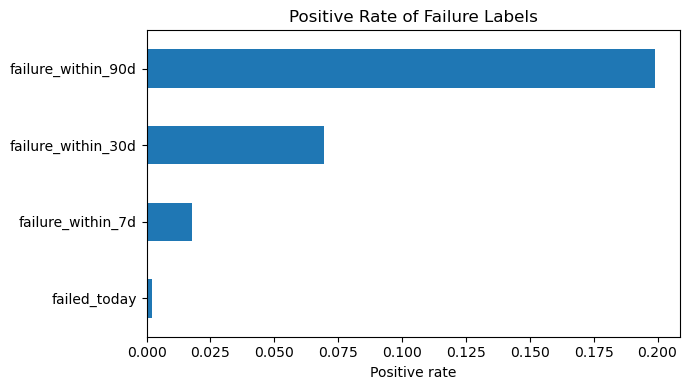

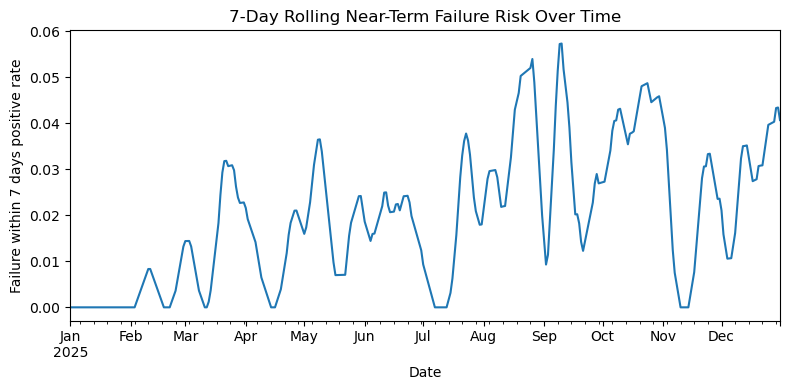

,count,mean,std,min,25%,50%,75%,max
efficiency_pct,32627.0,97.089,1.995,88.430,97.170,97.740,98.170,99.500
internal_temperature_c,32627.0,36.222,6.081,20.000,32.090,36.110,40.180,63.220
voltage_ripple,32627.0,2.601,0.763,0.552,2.026,2.596,3.137,5.749
current_harmonic_distortion_pct,32627.0,5.166,1.479,1.096,4.051,5.173,6.225,10.754
insulation_resistance_mohm,32627.0,81.578,7.366,58.030,75.970,81.390,87.320,102.140
restart_7d_sum,32627.0,2.248,3.254,0.000,0.000,1.000,2.000,24.000
errors_7d_sum,32627.0,2.991,4.314,0.000,1.000,2.000,3.000,32.000


In [5]:
# ================================================================
# 5. Exploratory visualisation
# ================================================================

df_raw = df_raw.sort_values(["inverter_id", "date"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 4))
df_raw[["failure_within_7d", "failure_within_30d", "failure_within_90d", "failed_today"]].mean().sort_values().plot(kind="barh", ax=ax)
ax.set_title("Positive Rate of Failure Labels")
ax.set_xlabel("Positive rate")
plt.tight_layout()
plt.savefig(PLOT_DIR / "failure_label_positive_rates.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
df_raw.groupby("date")["failure_within_7d"].mean().rolling(7, min_periods=1).mean().plot(ax=ax)
ax.set_title("7-Day Rolling Near-Term Failure Risk Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Failure within 7 days positive rate")
plt.tight_layout()
plt.savefig(PLOT_DIR / "rolling_failure_risk.png", dpi=150)
plt.show()

numeric_snapshot_cols = [
    "efficiency_pct", "internal_temperature_c", "voltage_ripple", 
    "current_harmonic_distortion_pct", "insulation_resistance_mohm", 
    "restart_7d_sum", "errors_7d_sum"
]

display(df_raw[numeric_snapshot_cols].describe().T.round(3))

In [6]:
# ================================================================
# 6. Advanced cyber-physical feature engineering
# ================================================================

# Helper function for score scaling.
# It converts a raw measurement into a 0-1 risk score using lower and upper bounds.
def bounded_score(series: pd.Series, low: float, high: float, invert: bool = False) -> pd.Series:
    score = ((series - low) / (high - low)).clip(0, 1)
    if invert:
        score = 1 - score
    return score.fillna(0)


def engineer_cyber_physical_features(input_df: pd.DataFrame, create_labels: bool = True) -> pd.DataFrame:
    """
    Create cyber-physical features from inverter telemetry.

    Important:
    - The dataset does not contain raw network logs or SCADA command logs.
    - The engineered features below represent the physical-process anomaly side of cyber-physical threat detection.
    - For production, these should be fused with actual network, IAM, and SCADA command features.
    """
    df = input_df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values(["inverter_id", "date"]).reset_index(drop=True)

    # ------------------------------
    # Calendar and seasonality features
    # ------------------------------
    df["day_of_week"] = df["date"].dt.dayofweek
    df["month"] = df["date"].dt.month
    df["day_of_year"] = df["date"].dt.dayofyear
    df["season_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
    df["season_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

    # ------------------------------
    # Lag and sudden-change features
    # These are useful for detecting abrupt operational shifts that may indicate abnormal commands or unstable behaviour.
    # ------------------------------
    lag_cols = [
        "efficiency_pct",
        "internal_temperature_c",
        "voltage_ripple",
        "current_harmonic_distortion_pct",
        "reactive_power_capability",
        "insulation_resistance_mohm",
        "restart_count_today",
        "error_code_count_today",
    ]

    for col in lag_cols:
        if col in df.columns:
            df[f"{col}_lag_1d"] = df.groupby("inverter_id")[col].shift(1)
            df[f"{col}_abs_change_1d"] = df.groupby("inverter_id")[col].diff().abs()

    # ------------------------------
    # Additional rolling features
    # Some rolling features already exist in the dataset. These add shorter and longer windows for anomaly detection.
    # ------------------------------
    rolling_cols = [
        "efficiency_pct",
        "internal_temperature_c",
        "voltage_ripple",
        "current_harmonic_distortion_pct",
        "restart_count_today",
        "error_code_count_today",
        "overload_events_today",
    ]

    for col in rolling_cols:
        if col in df.columns:
            for window in [3, 14]:
                df[f"{col}_{window}d_mean"] = (
                    df.groupby("inverter_id")[col]
                    .transform(lambda s: s.rolling(window, min_periods=1).mean())
                )
                df[f"{col}_{window}d_std"] = (
                    df.groupby("inverter_id")[col]
                    .transform(lambda s: s.rolling(window, min_periods=2).std())
                )

    # ------------------------------
    # Cooling response feature
    # A hot inverter with unexpectedly low fan speed may indicate hardware stress, control misconfiguration,
    # or telemetry/control inconsistency requiring investigation.
    # ------------------------------
    df["fan_speed_expected_min"] = np.where(
        df["internal_temperature_c"] >= 45, 3000,
        np.where(df["internal_temperature_c"] >= 40, 2600, 2200)
    )
    df["cooling_under_response_flag"] = (
        (df["internal_temperature_c"] >= 42) &
        (df["fan_speed_rpm"] < df["fan_speed_expected_min"])
    ).astype(int)

    # ------------------------------
    # Hard safety and instability flags
    # ------------------------------
    df["insulation_low_flag"] = (df["insulation_resistance_mohm"] < 70).astype(int)
    df["thermal_high_flag"] = (df["internal_temperature_c"] > 50).astype(int)
    df["reactive_power_drop_flag"] = (df["reactive_power_capability_abs_change_1d"] > 0.08).astype(int)
    df["voltage_ripple_high_flag"] = (df["voltage_ripple"] > 4.2).astype(int)
    df["harmonic_distortion_high_flag"] = (df["current_harmonic_distortion_pct"] > 8.0).astype(int)
    df["restart_burst_flag"] = (df["restart_7d_sum"] >= 10).astype(int)
    df["error_burst_flag"] = (df["errors_7d_sum"] >= 14).astype(int)

    # ------------------------------
    # Risk component scores
    # These are transparent, rule-based risk indicators used for alert explanation and weak label creation.
    # They are intentionally not used as model input later to reduce direct policy leakage.
    # ------------------------------
    df["event_burst_score"] = (
        bounded_score(df["restart_7d_sum"], 4, 16) * 0.35 +
        bounded_score(df["errors_7d_sum"], 5, 22) * 0.35 +
        bounded_score(df["restart_count_today"], 1, 5) * 0.15 +
        bounded_score(df["error_code_count_today"], 1, 6) * 0.15
    )

    df["electrical_instability_score"] = (
        bounded_score(df["voltage_ripple"], 3.2, 5.2) * 0.35 +
        bounded_score(df["current_harmonic_distortion_pct"], 6.5, 10.0) * 0.35 +
        bounded_score(df["reactive_power_capability"], 0.75, 0.98, invert=True) * 0.30
    )

    df["thermal_process_score"] = (
        bounded_score(df["internal_temperature_c"], 42, 55) * 0.40 +
        bounded_score(df["temp_stress_index"], 2, 13) * 0.25 +
        bounded_score(df["temperature_7d_mean"], 41, 51) * 0.20 +
        bounded_score(df["overload_events_today"], 1, 5) * 0.15
    )

    df["degradation_risk_score"] = (
        bounded_score(df["capacitor_degradation_indicator"], 0.60, 0.95) * 0.35 +
        bounded_score(df["insulation_resistance_mohm"], 65, 82, invert=True) * 0.35 +
        bounded_score(-df["efficiency_decline_7d"], 0.20, 1.30) * 0.30
    )

    df["unsafe_control_shift_score"] = (
        bounded_score(df["reactive_power_capability_abs_change_1d"], 0.04, 0.18) * 0.25 +
        bounded_score(df["voltage_ripple_abs_change_1d"], 0.60, 2.00) * 0.25 +
        bounded_score(df["current_harmonic_distortion_pct_abs_change_1d"], 1.00, 3.00) * 0.20 +
        bounded_score(df["internal_temperature_c_abs_change_1d"], 6.00, 14.00) * 0.15 +
        bounded_score(df["efficiency_pct_abs_change_1d"], 0.80, 2.00) * 0.15
    )

    df["cyber_physical_fusion_score"] = (
        0.28 * df["event_burst_score"] +
        0.25 * df["electrical_instability_score"] +
        0.20 * df["thermal_process_score"] +
        0.17 * df["degradation_risk_score"] +
        0.10 * df["unsafe_control_shift_score"]
    )

    # ------------------------------
    # Weak prototype labels
    # These are NOT true cyber attack labels. They are transparent proxy labels for prototyping.
    # ------------------------------
    if create_labels:
        critical_condition = (
            (df["insulation_resistance_mohm"] < 65) |
            (df["internal_temperature_c"] > 55) |
            ((df["restart_7d_sum"] >= 14) & (df["errors_7d_sum"] >= 18)) |
            (df.get("failed_today", 0) == 1)
        )

        near_term_failure_context = (
            (df.get("failure_within_7d", 0) == 1) &
            (df["cyber_physical_fusion_score"] >= 0.25)
        )

        df["cyber_physical_threat_flag"] = (
            (df["cyber_physical_fusion_score"] >= 0.45) |
            critical_condition |
            near_term_failure_context
        ).astype(int)

        df["threat_stage"] = pd.cut(
            df["cyber_physical_fusion_score"],
            bins=[-0.001, 0.15, 0.30, 0.45, 1.00],
            labels=["Normal", "Watch", "Suspicious", "Critical"],
        ).astype(str)
        df.loc[critical_condition, "threat_stage"] = "Critical"

    return df


df = engineer_cyber_physical_features(df_raw, create_labels=True)

print("Engineered dataset shape:", df.shape)
new_cols = [c for c in df.columns if c not in df_raw.columns]
print("Number of engineered columns:", len(new_cols))
print("First 30 engineered columns:")
print(new_cols[:30])

Engineered dataset shape: (32627, 108)
Number of engineered columns: 66
First 30 engineered columns:
['day_of_week', 'month', 'day_of_year', 'season_sin', 'season_cos', 'efficiency_pct_lag_1d', 'efficiency_pct_abs_change_1d', 'internal_temperature_c_lag_1d', 'internal_temperature_c_abs_change_1d', 'voltage_ripple_lag_1d', 'voltage_ripple_abs_change_1d', 'current_harmonic_distortion_pct_lag_1d', 'current_harmonic_distortion_pct_abs_change_1d', 'reactive_power_capability_lag_1d', 'reactive_power_capability_abs_change_1d', 'insulation_resistance_mohm_lag_1d', 'insulation_resistance_mohm_abs_change_1d', 'restart_count_today_lag_1d', 'restart_count_today_abs_change_1d', 'error_code_count_today_lag_1d', 'error_code_count_today_abs_change_1d', 'efficiency_pct_3d_mean', 'efficiency_pct_3d_std', 'efficiency_pct_14d_mean', 'efficiency_pct_14d_std', 'internal_temperature_c_3d_mean', 'internal_temperature_c_3d_std', 'internal_temperature_c_14d_mean', 'internal_temperature_c_14d_std', 'voltage_ripp

,count,mean,std,min,50%,75%,90%,95%,98%,99%,max
event_burst_score,32627.0,0.0500,0.1405,0.0,0.0000,0.0000,0.1990,0.4185,0.5742,0.6574,0.9794
electrical_instability_score,32627.0,0.0642,0.1217,0.0,0.0091,0.0743,0.1842,0.3195,0.5135,0.6100,0.9726
thermal_process_score,32627.0,0.0408,0.1110,0.0,0.0000,0.0001,0.1364,0.2750,0.4507,0.5665,0.9825
degradation_risk_score,32627.0,0.1221,0.1461,0.0,0.0778,0.1892,0.3052,0.4149,0.5676,0.6528,1.0000
unsafe_control_shift_score,32627.0,0.0961,0.0841,0.0,0.0795,0.1500,0.2139,0.2550,0.3054,0.3389,0.5339
cyber_physical_fusion_score,32627.0,0.0686,0.0972,0.0,0.0350,0.0721,0.1701,0.3035,0.4188,0.4763,0.7014


,count,rate
Normal / no threat,31717,0.9721
Cyber-physical threat,910,0.0279


,threat_stage,count,rate
0,Normal,28966,0.8878
1,Watch,1927,0.0591
2,Suspicious,1064,0.0326
3,Critical,670,0.0205


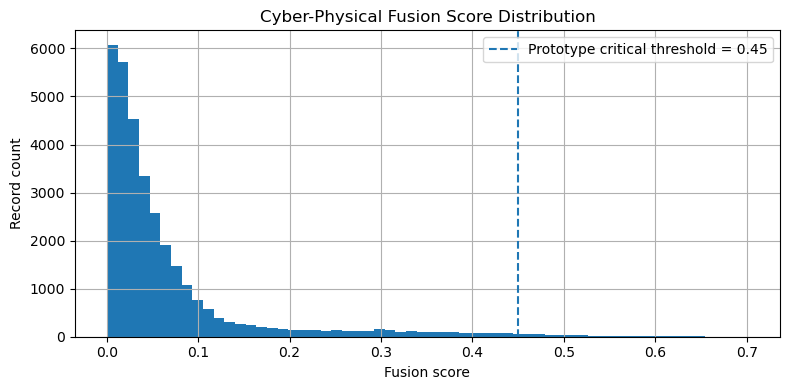

In [7]:
# ================================================================
# 7. Inspect engineered threat scores and weak-label distribution
# ================================================================

score_cols = [
    "event_burst_score",
    "electrical_instability_score",
    "thermal_process_score",
    "degradation_risk_score",
    "unsafe_control_shift_score",
    "cyber_physical_fusion_score",
]

display(df[score_cols].describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.98, 0.99]).T.round(4))

label_summary = pd.DataFrame({
    "count": df["cyber_physical_threat_flag"].value_counts().sort_index(),
    "rate": df["cyber_physical_threat_flag"].value_counts(normalize=True).sort_index().round(4)
})
label_summary.index = ["Normal / no threat", "Cyber-physical threat"]
display(label_summary)

stage_summary = df["threat_stage"].value_counts().rename_axis("threat_stage").reset_index(name="count")
stage_summary["rate"] = (stage_summary["count"] / len(df)).round(4)
display(stage_summary)

fig, ax = plt.subplots(figsize=(8, 4))
df["cyber_physical_fusion_score"].hist(bins=60, ax=ax)
ax.axvline(0.45, linestyle="--", label="Prototype critical threshold = 0.45")
ax.set_title("Cyber-Physical Fusion Score Distribution")
ax.set_xlabel("Fusion score")
ax.set_ylabel("Record count")
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "fusion_score_distribution.png", dpi=150)
plt.show()

## Leakage control

The weak label is created from risk rules because true cyber incident labels are unavailable. To avoid the model simply memorising the final risk policy, the training features exclude:

- `cyber_physical_fusion_score`
- the five component scores used to create the fusion score
- future-looking failure labels such as `failure_within_7d`, `failure_within_30d`, `failure_within_90d`
- `failed_today`, `rul_days`, and `is_censored`

The model is trained on raw telemetry, rolling indicators, lags, sudden-change features, and transparent safety flags. This is still a prototype weak-label setup, but it is cleaner than directly training on the final fusion score.

In [8]:
# ================================================================
# 8. Time-based train/test split
# ================================================================

TARGET = "cyber_physical_threat_flag"

# Time-based split is more realistic than random split because the model should generalise to future periods.
cutoff_date = df["date"].quantile(0.80)
train_df = df[df["date"] <= cutoff_date].copy()
test_df = df[df["date"] > cutoff_date].copy()

print("Cutoff date:", cutoff_date.date())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train positive rate:", round(train_df[TARGET].mean(), 4))
print("Test positive rate:", round(test_df[TARGET].mean(), 4))

Cutoff date: 2025-09-12
Train shape: (26166, 108)
Test shape: (6461, 108)
Train positive rate: 0.0221
Test positive rate: 0.0514


In [9]:
# ================================================================
# 9. Feature selection for modelling
# ================================================================

# Columns excluded from model training.
# The score columns are used for explainable alerting, not as model inputs.
EXCLUDE_COLUMNS = [
    "date",
    TARGET,
    "threat_stage",
    "cyber_physical_fusion_score",
    "event_burst_score",
    "electrical_instability_score",
    "thermal_process_score",
    "degradation_risk_score",
    "unsafe_control_shift_score",
    "failure_within_7d",
    "failure_within_30d",
    "failure_within_90d",
    "failed_today",
    "rul_days",
    "is_censored",
]

FEATURE_COLUMNS = [c for c in df.columns if c not in EXCLUDE_COLUMNS]

categorical_features = [
    c for c in FEATURE_COLUMNS
    if df[c].dtype == "object" or str(df[c].dtype).startswith("category")
]
numeric_features = [c for c in FEATURE_COLUMNS if c not in categorical_features]

print("Number of modelling features:", len(FEATURE_COLUMNS))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Categorical feature names:", categorical_features)

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET]
X_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET]

Number of modelling features: 93
Numeric features: 90
Categorical features: 3
Categorical feature names: ['inverter_id', 'manufacturer', 'climate_zone']


In [10]:
# ================================================================
# 10. Preprocessing and model definitions
# ================================================================

# Compatibility helper for different scikit-learn versions.
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", make_one_hot_encoder()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=7,
        min_samples_leaf=30,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=120,
        min_samples_leaf=3,
        max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
}

# Optional advanced model. Keep disabled by default so the notebook runs even without xgboost installed.
ENABLE_XGBOOST = False
if ENABLE_XGBOOST:
    try:
        from xgboost import XGBClassifier
        scale_pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
        models["XGBoost"] = XGBClassifier(
            n_estimators=250,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=RANDOM_STATE,
            tree_method="hist",
        )
    except Exception as exc:
        print("XGBoost skipped:", exc)

print("Models to train:", list(models.keys()))

Models to train: ['Decision Tree', 'Random Forest', 'Extra Trees']


In [11]:
# ================================================================
# 11. Train and evaluate supervised threat-detection models
# ================================================================

def safe_roc_auc(y_true, proba):
    try:
        return roc_auc_score(y_true, proba)
    except Exception:
        return np.nan


def safe_average_precision(y_true, proba):
    try:
        return average_precision_score(y_true, proba)
    except Exception:
        return np.nan

trained_models = {}
metrics_rows = []

for model_name, estimator in models.items():
    print(f"\nTraining: {model_name}")
    pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    trained_models[model_name] = pipeline

    test_proba = pipeline.predict_proba(X_test)[:, 1]
    test_pred = (test_proba >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
    precision = precision_score(y_test, test_pred, zero_division=0)
    recall = recall_score(y_test, test_pred, zero_division=0)
    f1 = f1_score(y_test, test_pred, zero_division=0)
    fpr = fp / max((fp + tn), 1)

    metrics_rows.append({
        "model": model_name,
        "roc_auc": safe_roc_auc(y_test, test_proba),
        "average_precision": safe_average_precision(y_test, test_proba),
        "precision_at_0.50": precision,
        "recall_at_0.50": recall,
        "f1_at_0.50": f1,
        "false_positive_rate_at_0.50": fpr,
        "true_positive": tp,
        "false_positive": fp,
        "true_negative": tn,
        "false_negative": fn,
    })

metrics_df = pd.DataFrame(metrics_rows).sort_values("roc_auc", ascending=False)
display(metrics_df.round(4))

best_model_name = metrics_df.iloc[0]["model"]
best_model = trained_models[best_model_name]
print("Best model selected by ROC-AUC:", best_model_name)

best_test_proba = best_model.predict_proba(X_test)[:, 1]
best_test_pred = (best_test_proba >= 0.50).astype(int)

print("\nClassification report for best model at threshold 0.50:")
print(classification_report(y_test, best_test_pred, digits=4, zero_division=0))


Training: Decision Tree

Training: Random Forest

Training: Extra Trees


,model,roc_auc,average_precision,precision_at_0.50,recall_at_0.50,f1_at_0.50,false_positive_rate_at_0.50,true_positive,false_positive,true_negative,false_negative
1,Random Forest,0.9938,0.8885,0.7781,0.7922,0.7851,0.0122,263,75,6054,69
2,Extra Trees,0.9934,0.9072,0.7456,0.8916,0.8121,0.0165,296,101,6028,36
0,Decision Tree,0.9691,0.8232,0.6125,0.9428,0.7426,0.0323,313,198,5931,19


Best model selected by ROC-AUC: Random Forest

Classification report for best model at threshold 0.50:
              precision    recall  f1-score   support

           0     0.9887    0.9878    0.9882      6129
           1     0.7781    0.7922    0.7851       332

    accuracy                         0.9777      6461
   macro avg     0.8834    0.8900    0.8867      6461
weighted avg     0.9779    0.9777    0.9778      6461



In [12]:
# ================================================================
# 12. Threshold tuning for security operations
# ================================================================

# In cyber/security use cases, the operating threshold matters.
# Lower threshold = catches more threats but creates more false alerts.
# Higher threshold = fewer false alerts but may miss threats.

def build_threshold_table(y_true, proba, thresholds=None):
    if thresholds is None:
        thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

    rows = []
    for threshold in thresholds:
        pred = (proba >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        precision = precision_score(y_true, pred, zero_division=0)
        recall = recall_score(y_true, pred, zero_division=0)
        f1 = f1_score(y_true, pred, zero_division=0)
        fpr = fp / max((fp + tn), 1)
        rows.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "false_positive_rate": fpr,
            "tp": tp,
            "fp": fp,
            "tn": tn,
            "fn": fn,
        })
    return pd.DataFrame(rows)

threshold_table = build_threshold_table(y_test, best_test_proba)

# Select an operational threshold.
# Preference: keep false positive rate <= 1.5% while maintaining recall >= 75%.
# If no threshold satisfies that, use the threshold with the highest F1 score.
candidates = threshold_table[
    (threshold_table["false_positive_rate"] <= 0.015) &
    (threshold_table["recall"] >= 0.75)
]

if len(candidates) > 0:
    selected_threshold_row = candidates.sort_values(["recall", "precision"], ascending=False).iloc[0]
else:
    selected_threshold_row = threshold_table.sort_values("f1", ascending=False).iloc[0]

SELECTED_THRESHOLD = float(selected_threshold_row["threshold"])
print("Selected operational threshold:", SELECTED_THRESHOLD)
print("Selected threshold metrics:")
display(pd.DataFrame([selected_threshold_row]).round(4))

# Show the top threshold options by F1.
display(threshold_table.sort_values("f1", ascending=False).head(10).round(4))

Selected operational threshold: 0.44
Selected threshold metrics:


,threshold,precision,recall,f1,false_positive_rate,tp,fp,tn,fn
39,0.44,0.7609,0.8434,0.8,0.0144,280.0,88.0,6041.0,52.0


,threshold,precision,recall,f1,false_positive_rate,tp,fp,tn,fn
32,0.37,0.7376,0.8976,0.8098,0.0173,298,106,6023,34
30,0.35,0.7221,0.9157,0.8074,0.0191,304,117,6012,28
31,0.36,0.7282,0.9036,0.8065,0.0183,300,112,6017,32
33,0.38,0.7387,0.8855,0.8055,0.0170,294,104,6025,38
29,0.34,0.7170,0.9157,0.8042,0.0196,304,120,6009,28
34,0.39,0.7423,0.8765,0.8039,0.0165,291,101,6028,41
35,0.40,0.7481,0.8675,0.8033,0.0158,288,97,6032,44
28,0.33,0.7080,0.9277,0.8031,0.0207,308,127,6002,24
36,0.41,0.7520,0.8584,0.8017,0.0153,285,94,6035,47
40,0.45,0.7694,0.8343,0.8006,0.0135,277,83,6046,55


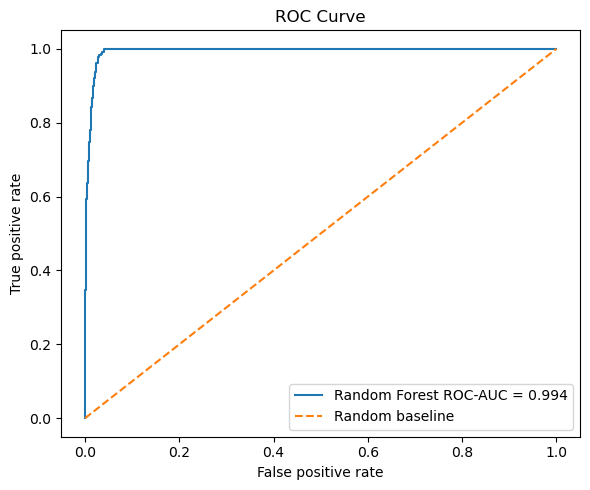

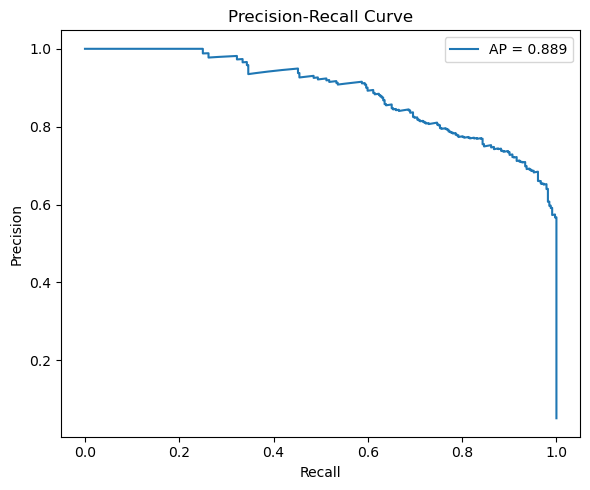

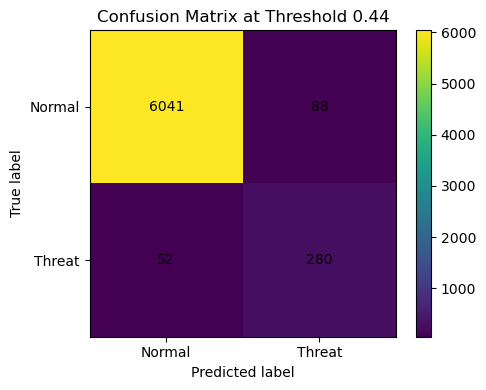

Classification report at selected threshold:
              precision    recall  f1-score   support

           0     0.9915    0.9856    0.9885      6129
           1     0.7609    0.8434    0.8000       332

    accuracy                         0.9783      6461
   macro avg     0.8762    0.9145    0.8943      6461
weighted avg     0.9796    0.9783    0.9789      6461



In [13]:
# ================================================================
# 13. Visualise ROC, Precision-Recall, and confusion matrix
# ================================================================

selected_pred = (best_test_proba >= SELECTED_THRESHOLD).astype(int)

# ROC curve
fpr_values, tpr_values, roc_thresholds = roc_curve(y_test, best_test_proba)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr_values, tpr_values, label=f"{best_model_name} ROC-AUC = {roc_auc_score(y_test, best_test_proba):.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "roc_curve.png", dpi=150)
plt.show()

# Precision-recall curve
precision_values, recall_values, pr_thresholds = precision_recall_curve(y_test, best_test_proba)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_values, precision_values, label=f"AP = {average_precision_score(y_test, best_test_proba):.3f}")
ax.set_title("Precision-Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "precision_recall_curve.png", dpi=150)
plt.show()

# Confusion matrix at selected threshold
cm = confusion_matrix(y_test, selected_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title(f"Confusion Matrix at Threshold {SELECTED_THRESHOLD:.2f}")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Normal", "Threat"])
ax.set_yticklabels(["Normal", "Threat"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(PLOT_DIR / "confusion_matrix_selected_threshold.png", dpi=150)
plt.show()

print("Classification report at selected threshold:")
print(classification_report(y_test, selected_pred, digits=4, zero_division=0))

,feature,importance
53,efficiency_pct_3d_mean,0.07959
55,efficiency_pct_14d_mean,0.06546
31,errors_7d_sum,0.06309
71,restart_count_today_14d_mean,0.05991
37,efficiency_pct_lag_1d,0.05872
24,efficiency_7d_mean,0.05833
12,efficiency_pct,0.05317
75,error_code_count_today_14d_mean,0.04872
25,efficiency_30d_mean,0.04142
72,restart_count_today_14d_std,0.03896


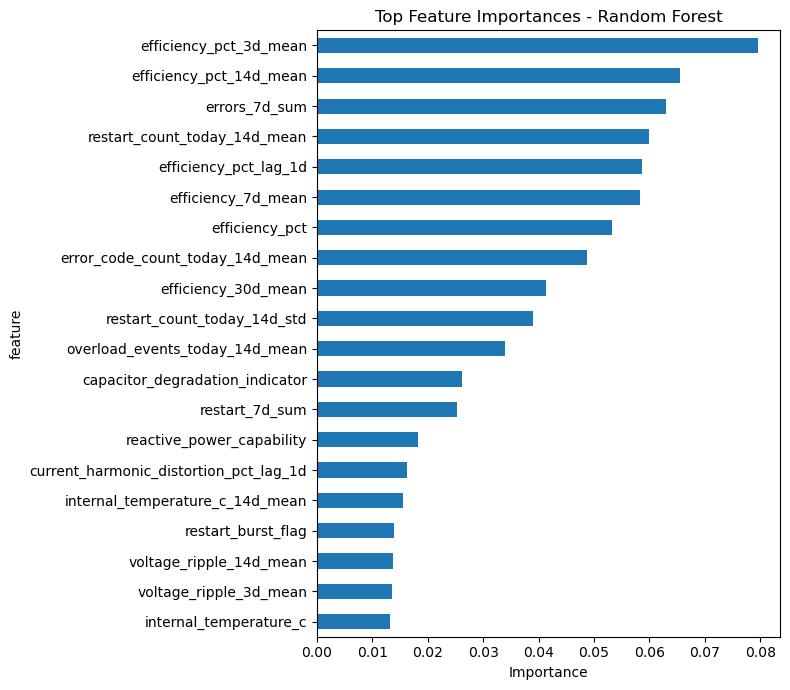

In [14]:
# ================================================================
# 14. Model explainability: feature importance
# ================================================================

# For tree-based models, extract feature importance after preprocessing.
def get_preprocessed_feature_names(fitted_pipeline: Pipeline) -> list:
    pre = fitted_pipeline.named_steps["preprocess"]
    names = []

    # Numeric names
    names.extend(numeric_features)

    # One-hot encoded categorical names
    if len(categorical_features) > 0:
        cat_pipe = pre.named_transformers_["cat"]
        onehot = cat_pipe.named_steps["onehot"]
        try:
            cat_names = onehot.get_feature_names_out(categorical_features).tolist()
        except Exception:
            cat_names = []
            for col, values in zip(categorical_features, onehot.categories_):
                cat_names.extend([f"{col}_{value}" for value in values])
        names.extend(cat_names)

    return names

model_step = best_model.named_steps["model"]
feature_names = get_preprocessed_feature_names(best_model)

if hasattr(model_step, "feature_importances_"):
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": model_step.feature_importances_,
    }).sort_values("importance", ascending=False)

    display(importance_df.head(25).round(5))

    fig, ax = plt.subplots(figsize=(8, 7))
    importance_df.head(20).sort_values("importance").plot(
        x="feature", y="importance", kind="barh", legend=False, ax=ax
    )
    ax.set_title(f"Top Feature Importances - {best_model_name}")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "feature_importance.png", dpi=150)
    plt.show()
else:
    print("Selected model does not expose built-in feature_importances_. Using permutation importance instead.")
    sample_size = min(3000, len(X_test))
    X_perm = X_test.sample(sample_size, random_state=RANDOM_STATE)
    y_perm = y_test.loc[X_perm.index]
    perm = permutation_importance(
        best_model, X_perm, y_perm, n_repeats=3, random_state=RANDOM_STATE, scoring="average_precision"
    )
    importance_df = pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "importance": perm.importances_mean,
    }).sort_values("importance", ascending=False)
    display(importance_df.head(25).round(5))

In [ ]:
# ================================================================
# 15. Transparent Decision Tree view for operator interpretation
# ================================================================

# Even if the best model is an ensemble, a shallow decision tree is useful for explaining logic to operators.
# This tree should not be treated as the final production model; it is an interpretability aid.

tree_model = trained_models["Decision Tree"]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model.named_steps["model"],
    feature_names=get_preprocessed_feature_names(tree_model),
    class_names=["Normal", "Threat"],
    filled=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Decision Tree Explanation View - Top 3 Levels")
plt.tight_layout()
plt.savefig(PLOT_DIR / "decision_tree_explanation.png", dpi=180)
plt.show()

Isolation Forest contamination: 0.0331
Isolation Forest threshold: 0.5886
Isolation Forest evaluation against weak labels:
              precision    recall  f1-score   support

           0     0.9975    0.9594    0.9780      6129
           1     0.5601    0.9548    0.7060       332

    accuracy                         0.9591      6461
   macro avg     0.7788    0.9571    0.8420      6461
weighted avg     0.9750    0.9591    0.9641      6461



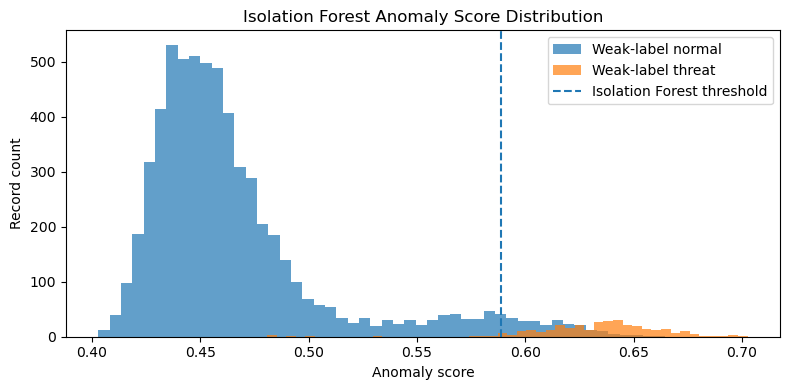

In [15]:
# ================================================================
# 16. Unsupervised anomaly detector: Isolation Forest
# ================================================================

# The supervised model learns from weak prototype labels.
# Isolation Forest adds an unsupervised layer that can flag unusual states even without attack labels.

numeric_preprocessor_for_iforest = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X_train_num = numeric_preprocessor_for_iforest.fit_transform(train_df[numeric_features])
X_test_num = numeric_preprocessor_for_iforest.transform(test_df[numeric_features])

# Contamination is the expected anomaly proportion. It is set conservatively based on weak-label prevalence.
contamination = float(np.clip(y_train.mean() * 1.5, 0.01, 0.08))
print("Isolation Forest contamination:", round(contamination, 4))

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
isolation_forest.fit(X_train_num)

# Higher score = more anomalous
train_iforest_score = -isolation_forest.score_samples(X_train_num)
test_iforest_score = -isolation_forest.score_samples(X_test_num)

# Use high percentile of training anomaly score as threshold.
IFOREST_THRESHOLD = float(np.quantile(train_iforest_score, 1 - contamination))
test_iforest_flag = (test_iforest_score >= IFOREST_THRESHOLD).astype(int)

print("Isolation Forest threshold:", round(IFOREST_THRESHOLD, 4))
print("Isolation Forest evaluation against weak labels:")
print(classification_report(y_test, test_iforest_flag, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(test_iforest_score[y_test == 0], bins=50, alpha=0.7, label="Weak-label normal")
ax.hist(test_iforest_score[y_test == 1], bins=50, alpha=0.7, label="Weak-label threat")
ax.axvline(IFOREST_THRESHOLD, linestyle="--", label="Isolation Forest threshold")
ax.set_title("Isolation Forest Anomaly Score Distribution")
ax.set_xlabel("Anomaly score")
ax.set_ylabel("Record count")
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "isolation_forest_scores.png", dpi=150)
plt.show()

## Threat classification and response logic

The model probability is useful, but cyber-physical operations also need explainable action guidance. The following section creates SOC-style output fields:

- `model_threat_probability`
- `isolation_forest_anomaly_score`
- `predicted_threat_flag`
- `severity_level`
- `likely_threat_type`
- `recommended_action`

This is not an offensive security workflow. It is a defensive monitoring and triage workflow for renewable-energy infrastructure.

In [16]:
# ================================================================
# 17. SOC-style alert generation
# ================================================================

def classify_severity(row) -> str:
    """Assign severity using model probability plus hard safety conditions."""
    p = row["model_threat_probability"]

    hard_critical = (
        (row.get("insulation_resistance_mohm", 999) < 65) or
        (row.get("internal_temperature_c", 0) > 55) or
        ((row.get("restart_7d_sum", 0) >= 14) and (row.get("errors_7d_sum", 0) >= 18))
    )

    if hard_critical or p >= 0.85:
        return "Critical"
    if p >= 0.65:
        return "High"
    if p >= SELECTED_THRESHOLD:
        return "Medium"
    if row.get("isolation_forest_anomaly_flag", 0) == 1:
        return "Watch"
    return "Low"


def classify_likely_threat_type(row) -> str:
    """Map telemetry and risk patterns to an operator-friendly explanation."""
    if row.get("insulation_resistance_mohm", 999) < 65 or row.get("internal_temperature_c", 0) > 55:
        return "SAFETY_CRITICAL_PROCESS_ANOMALY"
    if row.get("restart_7d_sum", 0) >= 10 or row.get("errors_7d_sum", 0) >= 14:
        return "RESTART_OR_ERROR_BURST_ANOMALY"
    if row.get("voltage_ripple", 0) > 4.2 or row.get("current_harmonic_distortion_pct", 0) > 8.0:
        return "POWER_QUALITY_OR_SETPOINT_ANOMALY"
    if row.get("reactive_power_capability_abs_change_1d", 0) > 0.08:
        return "POSSIBLE_UNAUTHORISED_CONTROL_SHIFT"
    if row.get("cooling_under_response_flag", 0) == 1:
        return "THERMAL_CONTROL_RESPONSE_ANOMALY"
    if row.get("capacitor_degradation_indicator", 0) > 0.75:
        return "DEGRADATION_DRIVEN_PHYSICAL_RISK"
    if row.get("isolation_forest_anomaly_flag", 0) == 1:
        return "UNSUPERVISED_TELEMETRY_ANOMALY"
    return "NO_MAJOR_THREAT_PATTERN"


def recommend_action(row) -> str:
    """Generate defensive SOC/operations recommendation."""
    severity = row["severity_level"]
    threat_type = row["likely_threat_type"]

    if severity == "Critical":
        return "Immediate human review; block autonomous control actions; validate SCADA commands; create urgent operations ticket."
    if threat_type == "POSSIBLE_UNAUTHORISED_CONTROL_SHIFT":
        return "Review command history and operator access logs; verify setpoint change; require operator approval before further control actions."
    if threat_type == "RESTART_OR_ERROR_BURST_ANOMALY":
        return "Investigate restart/error burst; compare with network and SCADA logs; temporarily rate-limit remote reset attempts."
    if threat_type == "POWER_QUALITY_OR_SETPOINT_ANOMALY":
        return "Check inverter setpoints, voltage control configuration, and grid-quality telemetry; escalate if anomaly persists."
    if severity in ["High", "Medium"]:
        return "SOC triage recommended; cross-check firewall, IAM, and SCADA command logs; monitor asset at increased frequency."
    if severity == "Watch":
        return "Monitor anomaly; add to watchlist and review if repeated within the next observation window."
    return "No immediate action; continue routine monitoring."


# Build alert dataframe for the test period.
alerts = test_df.copy()
alerts["model_threat_probability"] = best_test_proba
alerts["predicted_threat_flag"] = (alerts["model_threat_probability"] >= SELECTED_THRESHOLD).astype(int)
alerts["isolation_forest_anomaly_score"] = test_iforest_score
alerts["isolation_forest_anomaly_flag"] = test_iforest_flag
alerts["severity_level"] = alerts.apply(classify_severity, axis=1)
alerts["likely_threat_type"] = alerts.apply(classify_likely_threat_type, axis=1)
alerts["recommended_action"] = alerts.apply(recommend_action, axis=1)

alert_columns = [
    "date", "inverter_id", "manufacturer", "climate_zone",
    "model_threat_probability", "predicted_threat_flag",
    "isolation_forest_anomaly_score", "isolation_forest_anomaly_flag",
    "severity_level", "likely_threat_type", "recommended_action",
    "restart_7d_sum", "errors_7d_sum", "internal_temperature_c",
    "voltage_ripple", "current_harmonic_distortion_pct", "insulation_resistance_mohm",
    "reactive_power_capability", "cyber_physical_fusion_score", TARGET,
]

alerts_view = alerts[alert_columns].sort_values(
    ["severity_level", "model_threat_probability"],
    ascending=[True, False]
)

# Custom severity order for display.
severity_order = {"Critical": 0, "High": 1, "Medium": 2, "Watch": 3, "Low": 4}
alerts_view = alerts_view.assign(
    severity_rank=alerts_view["severity_level"].map(severity_order)
).sort_values(["severity_rank", "model_threat_probability"], ascending=[True, False]).drop(columns="severity_rank")

print("Top SOC-style alerts:")
display(alerts_view.head(25))

alert_summary = alerts_view["severity_level"].value_counts().rename_axis("severity_level").reset_index(name="count")
alert_summary["rate"] = (alert_summary["count"] / len(alerts_view)).round(4)
display(alert_summary)

Top SOC-style alerts:


,date,inverter_id,manufacturer,climate_zone,model_threat_probability,predicted_threat_flag,isolation_forest_anomaly_score,isolation_forest_anomaly_flag,severity_level,likely_threat_type,recommended_action,restart_7d_sum,errors_7d_sum,internal_temperature_c,voltage_ripple,current_harmonic_distortion_pct,insulation_resistance_mohm,reactive_power_capability,cyber_physical_fusion_score,cyber_physical_threat_flag
5711,2025-10-09,INV-0022,Huawei,Hot-Dry,0.988653,1,0.645268,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,14.0,16.0,50.68,3.736,7.146,72.08,0.782,0.483899,1
5712,2025-10-10,INV-0022,Huawei,Hot-Dry,0.988475,1,0.634355,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,11.0,18.0,53.15,3.844,7.700,72.60,0.854,0.471582,1
21629,2025-10-18,INV-0080,Huawei,Hot-Dry,0.988078,1,0.673732,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,14.0,30.0,45.35,4.270,9.341,66.43,0.877,0.568153,1
27579,2025-10-14,INV-0102,SMA,Hot-Dry,0.988044,1,0.634479,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,13.0,21.0,39.65,4.626,9.937,66.32,0.865,0.512102,1
27575,2025-10-10,INV-0102,SMA,Hot-Dry,0.987638,1,0.663515,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,14.0,27.0,43.15,4.624,8.954,65.14,0.757,0.571288,1
25486,2025-10-31,INV-0094,SMA,Humid-Subtropical,0.987084,1,0.631935,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,11.0,20.0,43.52,4.276,8.200,70.97,0.846,0.455090,1
13132,2025-10-15,INV-0048,SMA,Temperate,0.986748,1,0.652466,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,15.0,18.0,46.08,4.741,8.975,65.26,0.754,0.598500,1
23171,2025-10-12,INV-0085,Huawei,Hot-Dry,0.986304,1,0.660257,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,12.0,23.0,48.38,4.496,7.843,67.43,0.893,0.540029,1
28921,2025-10-02,INV-0106,SMA,Hot-Dry,0.986178,1,0.694021,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,13.0,22.0,51.75,4.374,8.278,69.10,0.754,0.632005,1
23169,2025-10-10,INV-0085,Huawei,Hot-Dry,0.984787,1,0.668127,1,Critical,RESTART_OR_ERROR_BURST_ANOMALY,Immediate human review; block autonomous contr...,12.0,24.0,45.77,4.485,7.996,71.67,0.895,0.516008,1


,severity_level,count,rate
0,Low,5874,0.9091
1,Critical,242,0.0375
2,Watch,180,0.0279
3,High,95,0.0147
4,Medium,70,0.0108


In [17]:
# ================================================================
# 18. Export prototype outputs
# ================================================================

# Save full test-period alert table.
alerts_output_path = OUTPUT_DIR / "cyber_physical_threat_alerts_test_period.csv"
alerts_view.to_csv(alerts_output_path, index=False)

# Save model metrics and threshold table.
metrics_output_path = OUTPUT_DIR / "model_metrics.csv"
threshold_output_path = OUTPUT_DIR / "threshold_tuning_table.csv"
feature_importance_output_path = OUTPUT_DIR / "feature_importance.csv"

metrics_df.to_csv(metrics_output_path, index=False)
threshold_table.to_csv(threshold_output_path, index=False)
importance_df.to_csv(feature_importance_output_path, index=False)

# Save models and metadata.
best_model_path = MODEL_DIR / "cyber_physical_threat_best_supervised_model.joblib"
iforest_path = MODEL_DIR / "cyber_physical_threat_isolation_forest.joblib"
numeric_preprocessor_path = MODEL_DIR / "numeric_preprocessor_for_isolation_forest.joblib"
metadata_path = MODEL_DIR / "model_metadata.json"

joblib.dump(best_model, best_model_path)
joblib.dump(isolation_forest, iforest_path)
joblib.dump(numeric_preprocessor_for_iforest, numeric_preprocessor_path)

metadata = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "project": "Cyber-Physical Threat Detection",
    "best_model_name": best_model_name,
    "selected_threshold": SELECTED_THRESHOLD,
    "iforest_threshold": IFOREST_THRESHOLD,
    "target": TARGET,
    "feature_columns": FEATURE_COLUMNS,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "data_limitation": "Current dataset does not include raw firewall, IAM, or SCADA command logs. Prototype uses physical-process anomaly features and weak labels.",
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved outputs:")
for path in [alerts_output_path, metrics_output_path, threshold_output_path, feature_importance_output_path, best_model_path, iforest_path, numeric_preprocessor_path, metadata_path]:
    print("-", path)

Saved outputs:
- .- .- .- .- .- .- .- .

In [18]:
# ================================================================
# 19. Reusable scoring function for new data
# ================================================================

# This function shows how the prototype could be reused on a new batch of inverter telemetry.
# For production, add real network, IAM, and SCADA command features before scoring.

def score_new_cyber_physical_batch(new_data: pd.DataFrame) -> pd.DataFrame:
    """
    Score new inverter telemetry records using the trained supervised model and Isolation Forest.

    Parameters
    ----------
    new_data : pd.DataFrame
        New raw telemetry with the same base columns as the training dataset.

    Returns
    -------
    pd.DataFrame
        Scored alerts with probability, anomaly score, severity, likely threat type, and recommended action.
    """
    scored = engineer_cyber_physical_features(new_data, create_labels=False)

    # Ensure all training features exist. Missing columns are filled with NaN and handled by imputers.
    for col in FEATURE_COLUMNS:
        if col not in scored.columns:
            scored[col] = np.nan

    scored_X = scored[FEATURE_COLUMNS]
    scored["model_threat_probability"] = best_model.predict_proba(scored_X)[:, 1]
    scored["predicted_threat_flag"] = (scored["model_threat_probability"] >= SELECTED_THRESHOLD).astype(int)

    scored_num = numeric_preprocessor_for_iforest.transform(scored[numeric_features])
    scored_iforest_score = -isolation_forest.score_samples(scored_num)
    scored["isolation_forest_anomaly_score"] = scored_iforest_score
    scored["isolation_forest_anomaly_flag"] = (scored_iforest_score >= IFOREST_THRESHOLD).astype(int)

    scored["severity_level"] = scored.apply(classify_severity, axis=1)
    scored["likely_threat_type"] = scored.apply(classify_likely_threat_type, axis=1)
    scored["recommended_action"] = scored.apply(recommend_action, axis=1)

    return scored


# Example scoring run using the provided sample file if available.
if len(sample_df) > 0:
    scored_sample = score_new_cyber_physical_batch(sample_df)
    display(scored_sample[[
        "date", "inverter_id", "model_threat_probability", "predicted_threat_flag",
        "isolation_forest_anomaly_score", "isolation_forest_anomaly_flag",
        "severity_level", "likely_threat_type", "recommended_action"
    ]].head(20))

,date,inverter_id,model_threat_probability,predicted_threat_flag,isolation_forest_anomaly_score,isolation_forest_anomaly_flag,severity_level,likely_threat_type,recommended_action
0,2025-01-01,INV-0001,0.0,0,0.404885,0,Low,NO_MAJOR_THREAT_PATTERN,No immediate action; continue routine monitoring.
1,2025-01-02,INV-0001,0.0,0,0.430404,0,Low,NO_MAJOR_THREAT_PATTERN,No immediate action; continue routine monitoring.
2,2025-01-03,INV-0001,0.0,0,0.435390,0,Low,POSSIBLE_UNAUTHORISED_CONTROL_SHIFT,Review command history and operator access log...
3,2025-01-04,INV-0001,0.0,0,0.439851,0,Low,POSSIBLE_UNAUTHORISED_CONTROL_SHIFT,Review command history and operator access log...
4,2025-01-05,INV-0001,0.0,0,0.418586,0,Low,POSSIBLE_UNAUTHORISED_CONTROL_SHIFT,Review command history and operator access log...
5,2025-01-06,INV-0001,0.0,0,0.414653,0,Low,NO_MAJOR_THREAT_PATTERN,No immediate action; continue routine monitoring.
6,2025-01-07,INV-0001,0.0,0,0.431838,0,Low,NO_MAJOR_THREAT_PATTERN,No immediate action; continue routine monitoring.
7,2025-01-08,INV-0001,0.0,0,0.421864,0,Low,POSSIBLE_UNAUTHORISED_CONTROL_SHIFT,Review command history and operator access log...
8,2025-01-09,INV-0001,0.0,0,0.441164,0,Low,POSSIBLE_UNAUTHORISED_CONTROL_SHIFT,Review command history and operator access log...
9,2025-01-10,INV-0001,0.0,0,0.441559,0,Low,NO_MAJOR_THREAT_PATTERN,No immediate action; continue routine monitoring.


## Production extension plan

The current notebook is a strong prototype for the **physical-process anomaly layer**. To make it a full cyber-physical threat detection system, the next production version should add the following data tables and feature groups.

### 1. Network intrusion detection features

| Feature group | Example features |
|---|---|
| Flow volume | packets per minute, bytes per minute, connection count |
| Source/destination behaviour | unique source IPs, unusual destination, external-to-internal connections |
| Protocol behaviour | protocol type, port frequency, uncommon port flag |
| Traffic anomaly | packet-size z-score, burst score, connection-rate spike |

### 2. SCADA command anomaly features

| Feature group | Example features |
|---|---|
| Command frequency | commands per minute/hour, repeated commands |
| Command sequence | unusual sequence, command after-hours, command gap time |
| Control-setpoint change | reactive power setpoint change, voltage control change, reset command flag |
| Operator context | operator ID, role, approval status, device history |

### 3. IAM and access-log features

| Feature group | Example features |
|---|---|
| Authentication | failed login count, MFA failure, impossible travel |
| Privilege use | privileged action count, new device login, service-account access |
| Session behaviour | unusual login hour, session duration anomaly, unusual asset access |

### 4. Cyber-physical fusion logic

The final model should combine:

```text
Network anomaly score
+ SCADA command anomaly score
+ IAM access-risk score
+ Physical process anomaly score
+ Asset criticality score
= Final cyber-physical threat probability and severity
```

This will allow the system to detect cases where the cyber signal is weak alone, but becomes highly suspicious when followed by abnormal physical behaviour, such as restarts, voltage instability, unexpected reactive power changes, or sudden thermal stress.

## Prototype summary

This notebook created a detailed Cyber-Physical Threat Detection prototype for the Omni-Grid platform.

Completed components:

- Loaded and audited the synthetic cyber-physical dataset.
- Built advanced telemetry, lag, rolling, event-burst, control-shift, and safety-risk features.
- Created transparent weak labels for cyber-physical threat detection because true cyber attack labels are unavailable.
- Trained supervised models using a time-based train/test split.
- Added threshold tuning for SOC-style operations.
- Added an unsupervised Isolation Forest anomaly-detection layer.
- Produced explainability outputs using feature importance and decision-tree visualisation.
- Generated SOC-style alerts with severity, likely threat type, and recommended action.
- Exported model files, metrics, threshold tables, feature importance, plots, metadata, and alert outputs.

Important limitation:

The current dataset does not include raw network traffic, SCADA commands, or IAM access logs. Therefore, this prototype should be presented as the physical-process anomaly layer of the full cyber-physical threat detection architecture. The full production model should add real cyber telemetry and analyst-verified incident labels.